In [1]:
# Group B - Assignment 5
# Problem Statement:
# Implement K-Means clustering / hierarchical clustering on sales_data_sample.csv dataset.
# Determine the number of clusters using the elbow method.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [3]:
print("=== Loading Dataset ===")
# Encoded with Latin-1 to prevent standard UTF-8 parsing errors
df = pd.read_csv("sales_data_sample.csv", encoding="Latin-1")

print("\n--- Initial Dataset Head ---")
print(df.head())

print("\n--- Initial Dataset Info ---")
df.info()

print("\n--- Initial Dataset Shape ---")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])

=== Loading Dataset ===

--- Initial Dataset Head ---
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC  

In [4]:
print("=== Pre-processing and Feature Selection ===")

# Select continuous numerical columns for distance-based clustering
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
X = df[features]

print("\n--- Missing Values in Features ---")
print(X.isnull().sum())

# Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nFeatures scaled successfully.")
print("Scaled Features Shape:", X_scaled.shape)

=== Pre-processing and Feature Selection ===

--- Missing Values in Features ---
QUANTITYORDERED    0
PRICEEACH          0
SALES              0
MSRP               0
dtype: int64

Features scaled successfully.
Scaled Features Shape: (2823, 4)


=== Determining Optimal K using Elbow Method ===


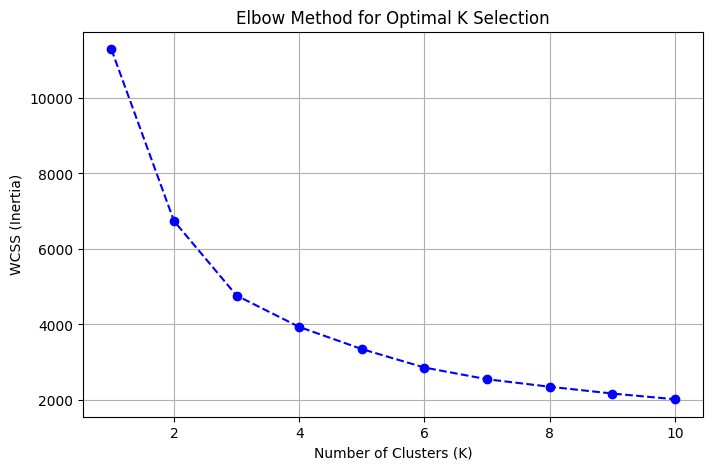


Check the bend in the Elbow plot (typically K=3 or K=4).


In [5]:
print("=== Determining Optimal K using Elbow Method ===")

wcss = []  # Within-Cluster Sum of Squares
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plotting the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', linestyle='--', color='b')
plt.title('Elbow Method for Optimal K Selection')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

print("\nCheck the bend in the Elbow plot (typically K=3 or K=4).")

In [6]:
print("=== Implementing K-Means Clustering ===")

# Applying K-Means with optimal K = 3
optimal_k = 3
kmeans_model = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
cluster_labels = kmeans_model.fit_predict(X_scaled)

# Append cluster assignment to dataset
df['Cluster'] = cluster_labels

print(f"\n--- Cluster Assignments Count (K = {optimal_k}) ---")
print(df['Cluster'].value_counts())

print("\n--- Mean Values per Cluster ---")
print(df.groupby('Cluster')[features].mean())

=== Implementing K-Means Clustering ===

--- Cluster Assignments Count (K = 3) ---
Cluster
2    996
0    975
1    852
Name: count, dtype: int64

--- Mean Values per Cluster ---
         QUANTITYORDERED  PRICEEACH        SALES        MSRP
Cluster                                                     
0              35.208205  59.551169  2101.076482   64.145641
1              43.723005  97.479261  5720.080669  127.893192
2              27.597390  95.435090  3123.062801  113.266064


=== Visualizing Clusters ===


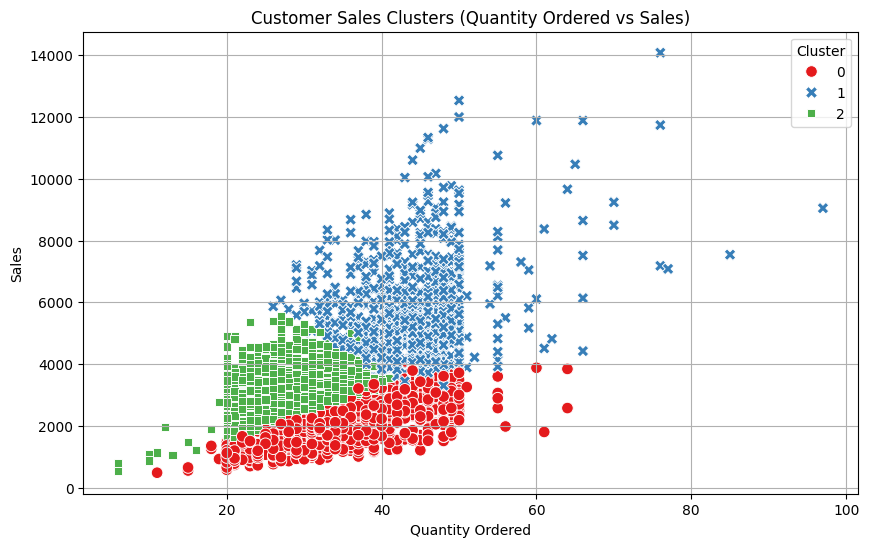

In [7]:
print("=== Visualizing Clusters ===")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=df['QUANTITYORDERED'], 
    y=df['SALES'], 
    hue=df['Cluster'], 
    palette='Set1', 
    style=df['Cluster'],
    s=70
)

plt.title("Customer Sales Clusters (Quantity Ordered vs Sales)")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.grid(True)
plt.show()